
# Univariate Analysis



## 1. Understanding Univariate Analysis

Univariate analysis is the process of analyzing one variable at a time.

It helps us understand:
- The distribution of values
- The most common values
- The center and spread of numerical data
- The frequency of categories
- Missing values and unusual observations

**Example:** Analyzing only the salary column to understand salary distribution.

**AI/ML relevance:** It helps us understand individual features before preparing data for a machine learning model.


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")



## 2. Load the Dataset

We use the same dataset from the previous notebooks.

The `read_csv()` function loads the CSV file into a Pandas DataFrame.


In [3]:

df = pd.read_csv("ml_training_data.csv")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())


Dataset loaded successfully!
Number of rows: 5
Number of columns: 3


,Study_Hours,Attendance,Exam_Marks
0,2,60,50
1,3,65,55
2,4,75,65
3,5,85,75
4,6,95,90



## 3. Identify Numerical and Categorical Features

Numerical features contain numeric values. Categorical features represent groups or labels.

We identify these feature types so that we can apply suitable statistical methods and visualizations.


In [4]:

numerical_cols = df.select_dtypes(include=np.number).columns.tolist()

categorical_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:")
print(numerical_cols)

print("\nCategorical features:")
print(categorical_cols)


Numerical features:
['Study_Hours', 'Attendance', 'Exam_Marks']

Categorical features:
[]



## 4. Summary Statistics

Summary statistics help us understand the center and spread of numerical data.

- Mean: Average value.
- Median: Middle value.
- Standard deviation: Measures how spread out the values are.
- Minimum: Smallest value.
- Maximum: Largest value.


In [5]:

if numerical_cols:
    display(df[numerical_cols].describe().T)
else:
    print("No numerical features found.")


,count,mean,std,min,25%,50%,75%,max
Study_Hours,5.0,4.0,1.581139,2.0,3.0,4.0,5.0,6.0
Attendance,5.0,76.0,14.317821,60.0,65.0,75.0,85.0,95.0
Exam_Marks,5.0,67.0,16.046807,50.0,55.0,65.0,75.0,90.0



## 5. Numerical Feature Analysis

We select one numerical feature and calculate its mean, median, mode, range, and standard deviation.

This helps us understand the typical value and variability of the feature.


In [6]:

# Select a meaningful numerical feature.
# Change this column name if the first column is an ID.
if numerical_cols:
    num_col = numerical_cols[0]
    values = df[num_col].dropna()

    print("Selected feature:", num_col)
    print("Valid observations:", len(values))

    if not values.empty:
        print("Mean:", values.mean())
        print("Median:", values.median())
        print("Mode:", values.mode().tolist())
        print("Minimum:", values.min())
        print("Maximum:", values.max())
        print("Range:", values.max() - values.min())
        print("Standard deviation:", values.std())
else:
    print("No numerical feature available.")


Selected feature: Study_Hours
Valid observations: 5
Mean: 4.0
Median: 4.0
Mode: [2, 3, 4, 5, 6]
Minimum: 2
Maximum: 6
Range: 4
Standard deviation: 1.5811388300841898


## 6. Histogram

A histogram shows the frequency of numerical values within different ranges.

It helps us understand the shape of a distribution, where values are concentrated, and whether the distribution appears skewed.


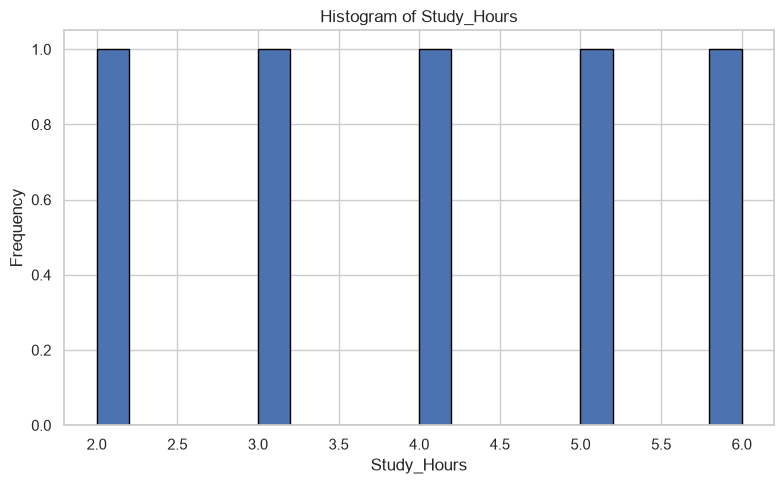

In [7]:

if numerical_cols:
    num_col = numerical_cols[0]
    values = df[num_col].dropna()

    if not values.empty:
        plt.figure(figsize=(8, 5))
        plt.hist(values, bins=20, edgecolor="black")
        plt.title(f"Histogram of {num_col}")
        plt.xlabel(num_col)
        plt.ylabel("Frequency")
        plt.tight_layout()
        plt.show()



### Interpretation

- Tall bars show ranges containing more observations.
- A roughly balanced shape may indicate a symmetric distribution.
- A longer tail on one side may indicate skewness.
- Separate peaks may suggest groups within the data.

The actual interpretation depends on the histogram produced by the dataset.



## 7. Box Plot

A box plot displays the median, quartiles, and spread of numerical data.

Points beyond the whiskers may be potential outliers. They should be investigated rather than automatically removed.


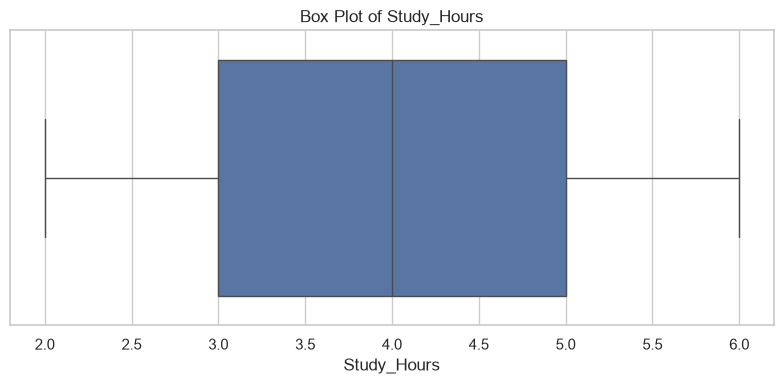

In [8]:

if numerical_cols:
    num_col = numerical_cols[0]
    values = df[num_col].dropna()

    if not values.empty:
        plt.figure(figsize=(8, 4))
        sns.boxplot(x=values)
        plt.title(f"Box Plot of {num_col}")
        plt.xlabel(num_col)
        plt.tight_layout()
        plt.show()



## 8. Categorical Feature Analysis

Categorical analysis helps us understand how frequently each category appears.

Frequency counts identify common categories, rare categories, and possible imbalances.


In [9]:

if categorical_cols:
    cat_col = categorical_cols[0]

    print("Selected categorical feature:", cat_col)
    display(df[cat_col].value_counts(dropna=False).to_frame(
        name="Frequency"
    ))
else:
    print("No categorical features found.")


No categorical features found.



## 9. Bar Chart

A bar chart compares the frequency of categories.

It helps us identify the most common categories and determine whether some categories have very few observations.


In [10]:

if categorical_cols:
    cat_col = categorical_cols[0]

    counts = (
        df[cat_col]
        .astype("string")
        .fillna("Missing")
        .value_counts()
        .head(15)
    )

    if not counts.empty:
        plt.figure(figsize=(9, 5))
        counts.plot(kind="bar", edgecolor="black")
        plt.title(f"Category Frequency: {cat_col}")
        plt.xlabel(cat_col)
        plt.ylabel("Frequency")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()



## 10. Missing Value Analysis

Missing values occur when observations are not available for some features.

We calculate the number and percentage of missing values to understand how complete each feature is.


In [11]:

missing_count = df.isnull().sum()
missing_percentage = (missing_count / len(df) * 100).round(2)

missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percentage
})

display(missing_summary)

if df.isnull().sum().sum() == 0:
    print("No missing values found.")


,Missing Count,Missing Percentage
Study_Hours,0,0.0
Attendance,0,0.0
Exam_Marks,0,0.0


No missing values found.



## 11. Skewness Analysis

Skewness describes the asymmetry of a numerical distribution.

- Skewness near zero: approximately symmetric distribution.
- Positive skewness: longer tail toward higher values.
- Negative skewness: longer tail toward lower values.

Skewness should be interpreted together with a histogram and knowledge of the feature.


In [12]:

if numerical_cols:
    skewness = df[numerical_cols].skew().round(2)
    display(skewness.to_frame(name="Skewness"))
else:
    print("No numerical features available.")


,Skewness
Study_Hours,0.00
Attendance,0.31
Exam_Marks,0.61



## 12. Mode Analysis

The mode is the most frequently occurring value in a feature.

It helps identify the most common category or numerical value in a dataset.


In [13]:

for col in df.columns:
    modes = df[col].mode(dropna=True)

    if not modes.empty:
        print(f"{col}: {modes.iloc[0]}")
    else:
        print(f"{col}: No available value")


Study_Hours: 2
Attendance: 60
Exam_Marks: 50



## 13. Mean and Median Comparison

The mean and median help describe the center of numerical data.

If the mean and median are very different, the distribution may be skewed or influenced by extreme values. This is a useful clue, but it does not prove that outliers exist.


In [14]:

if numerical_cols:
    comparison = pd.DataFrame({
        "Mean": df[numerical_cols].mean(),
        "Median": df[numerical_cols].median()
    })

    comparison["Mean - Median"] = (
        comparison["Mean"] - comparison["Median"]
    )

    display(comparison.round(2))


,Mean,Median,Mean - Median
Study_Hours,4.0,4.0,0.0
Attendance,76.0,75.0,1.0
Exam_Marks,67.0,65.0,2.0



## 14. Distribution of Numerical Features

We create histograms for numerical features to compare their individual distributions.

Each histogram analyzes one feature at a time.


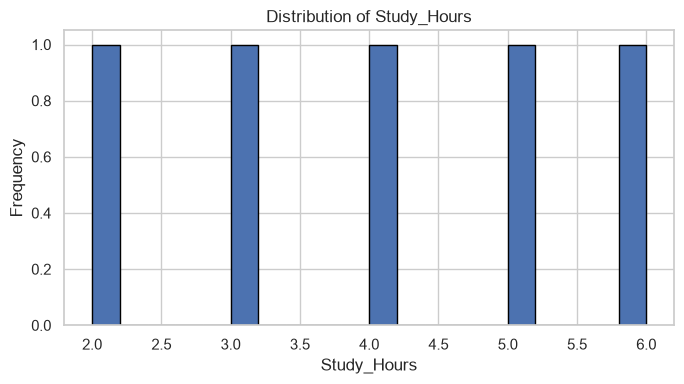

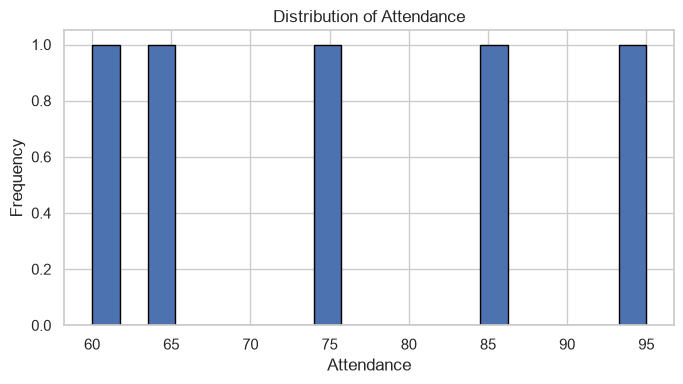

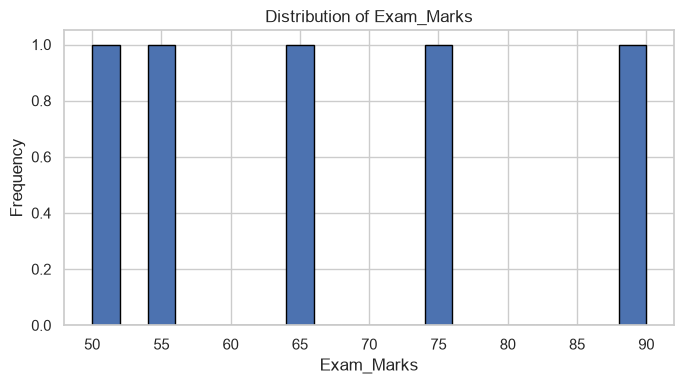

In [15]:

for col in numerical_cols:
    values = df[col].dropna()

    if values.empty:
        continue

    plt.figure(figsize=(7, 4))
    plt.hist(values, bins=20, edgecolor="black")
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()



## 15. AI/ML Relevance

Univariate analysis is useful in machine learning because it helps us:

- Understand individual features before model training.
- Identify missing values and unusual observations.
- Recognize skewed numerical features.
- Understand category frequencies and possible imbalance.
- Decide whether encoding, scaling, or transformation should be investigated.

Univariate analysis does not establish relationships between features or prove that a feature predicts the target variable.
